# Data Science Research Capstone: Weather and Hourly Bike-Sharing Demand

**Research question:** Among hourly observations, are poor-weather hours associated with fewer bike rentals after adjusting for hour, working-day status, season, and year?

The analysis is observational and follows the preregistered exposure and model. It uses the supplied UCI hourly dataset; the target is not used to define weather exposure.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import statsmodels.formula.api as smf
import statsmodels.api as sm
from statsmodels.stats.diagnostic import het_breuschpagan
from pathlib import Path
sns.set_theme(style="whitegrid")
DATA = Path("../data/raw/hour.csv")
if not DATA.exists(): DATA = Path("/mnt/data/hour.csv")
raw = pd.read_csv(DATA)
print("Shape:", raw.shape, "Missing:", raw.isna().sum().sum(), "Duplicates:", raw.duplicated().sum())
print("Dates:", raw.dteday.min(), "to", raw.dteday.max())
display(raw.head())

Shape: (17379, 17) Missing: 0 Duplicates: 0
Dates: 2011-01-01 to 2012-12-31


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


## 1. Preprocessing and descriptive statistics
Good weather is `weathersit` 1–2; poor weather is 3–4. The outcome is `cnt`; `casual` and `registered` are excluded from predictors because they are components of total count.

In [2]:
data = raw.drop_duplicates().copy()
data = data[data.weathersit.isin([1,2,3,4]) & (data.cnt >= 0)].dropna(
    subset=["hr","workingday","season","yr","weathersit","cnt"]).copy()
data["poor_weather"] = (data.weathersit >= 3).astype(int)
data["log_cnt"] = np.log1p(data.cnt)
desc = data.groupby("poor_weather").cnt.agg(["count","mean","median","std"])
display(desc)
print("Poor-weather share:", round(data.poor_weather.mean()*100,2), "%")

,count,mean,median,std
poor_weather,,,,
0,15957,196.410666,152.0,183.445187
1,1422,111.500703,63.0,133.682656


Poor-weather share: 8.18 %


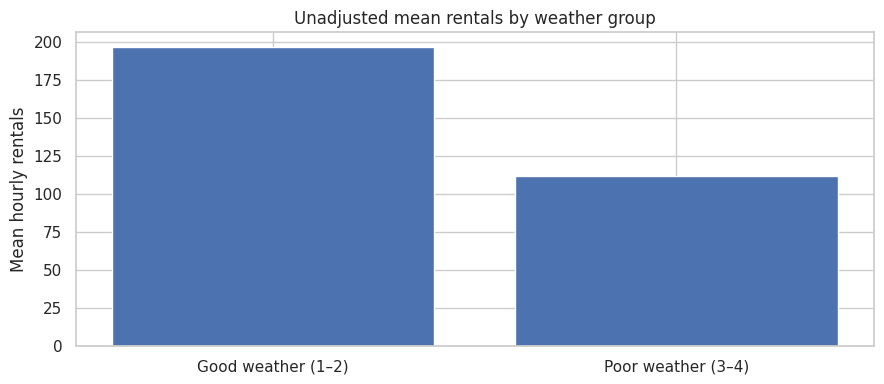

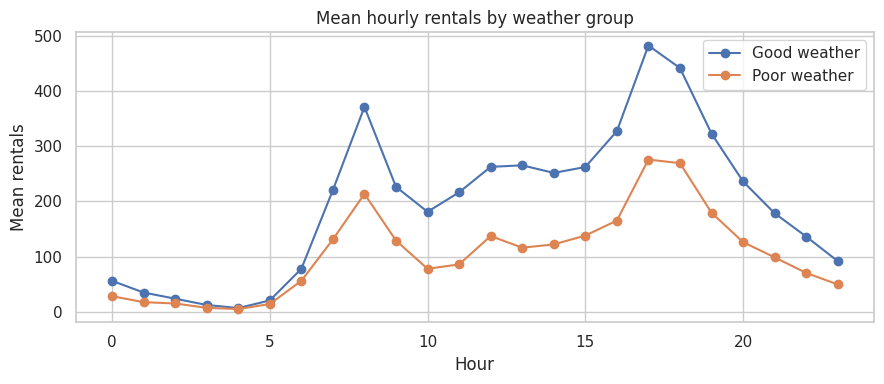

In [3]:
fig, ax = plt.subplots(figsize=(9,4))
ax.bar(["Good weather (1–2)","Poor weather (3–4)"], desc["mean"])
ax.set_ylabel("Mean hourly rentals"); ax.set_title("Unadjusted mean rentals by weather group")
plt.tight_layout(); plt.show()

hourly = data.groupby(["hr","poor_weather"]).cnt.mean().unstack()
hourly.plot(figsize=(9,4), marker="o")
plt.title("Mean hourly rentals by weather group"); plt.xlabel("Hour"); plt.ylabel("Mean rentals")
plt.legend(["Good weather","Poor weather"]); plt.tight_layout(); plt.show()

## 2. Preregistered primary model

`log1p(cnt) ~ poor_weather + C(hr) + C(workingday) + C(season) + C(yr)`

OLS coefficient inference uses HC3 heteroskedasticity-robust standard errors. The primary exposure hypothesis is directional (poor weather associated with lower demand); report the two-sided 95% CI and two-sided p-value as well as the one-sided p-value.

In [4]:
primary = smf.ols("log_cnt ~ poor_weather + C(hr) + C(workingday) + C(season) + C(yr)", data=data).fit(cov_type="HC3")
b = primary.params["poor_weather"]; ci = primary.conf_int().loc["poor_weather"]
result = pd.DataFrame({"estimate":[b], "HC3_SE":[primary.bse["poor_weather"]],
                       "CI_low":[ci.iloc[0]], "CI_high":[ci.iloc[1]],
                       "p_two_sided":[primary.pvalues["poor_weather"]],
                       "p_one_sided_directional":[primary.pvalues["poor_weather"]/2],
                       "exp_beta":[np.exp(b)], "exp_CI_low":[np.exp(ci.iloc[0])],
                       "exp_CI_high":[np.exp(ci.iloc[1])], "R_squared":[primary.rsquared]})
display(result.T.rename(columns={0:"poor_weather"}))
print(primary.summary())

,poor_weather
estimate,-6.584473e-01
HC3_SE,2.163194e-02
CI_low,-7.008451e-01
CI_high,-6.160494e-01
p_two_sided,1.692793e-203
p_one_sided_directional,8.463966e-204
exp_beta,5.176545e-01
exp_CI_low,4.961658e-01
exp_CI_high,5.400738e-01
R_squared,8.089686e-01


                            OLS Regression Results                            
Dep. Variable:                log_cnt   R-squared:                       0.809
Model:                            OLS   Adj. R-squared:                  0.809
Method:                 Least Squares   F-statistic:                     2828.
Date:                Fri, 30 Oct 2026   Prob (F-statistic):               0.00
Time:                        19:04:41   Log-Likelihood:                -16343.
No. Observations:               17379   AIC:                         3.275e+04
Df Residuals:                   17349   BIC:                         3.298e+04
Df Model:                          29                                         
Covariance Type:                  HC3                                         
                         coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------
Intercept              2.9421      0

## 3. Diagnostics

Breusch-Pagan LM: 4660.884121931135 p-value: 0.0
Studentized residuals with |value| > 3: 133


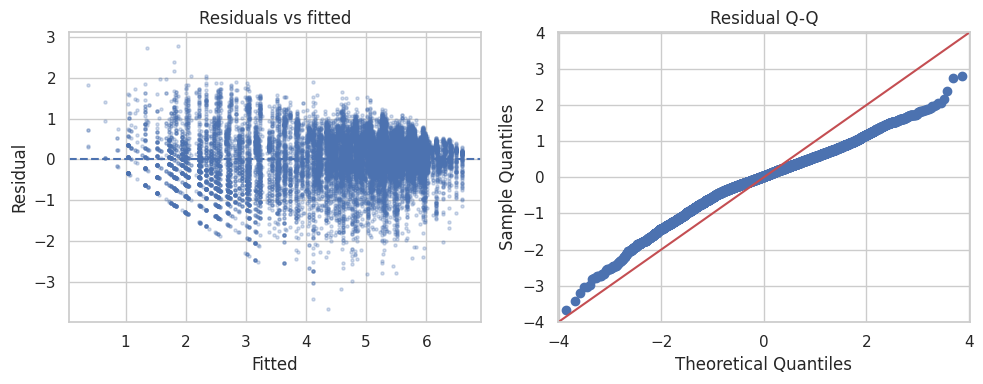

In [5]:
bp = het_breuschpagan(primary.resid, primary.model.exog)
print("Breusch-Pagan LM:", bp[0], "p-value:", bp[1])
infl = primary.get_influence()
print("Studentized residuals with |value| > 3:", int((np.abs(infl.resid_studentized_internal)>3).sum()))
fig, ax = plt.subplots(1,2,figsize=(10,4))
ax[0].scatter(primary.fittedvalues, primary.resid, s=5, alpha=.25); ax[0].axhline(0,ls="--")
ax[0].set(title="Residuals vs fitted", xlabel="Fitted", ylabel="Residual")
sm.qqplot(primary.resid, line="45", ax=ax[1])
ax[1].set_title("Residual Q-Q")
plt.tight_layout(); plt.show()

## 4. Secondary robustness analyses
These models are sensitivity checks and do not replace the preregistered primary model.

In [6]:
raw_model = smf.ols("cnt ~ poor_weather + C(hr)+C(workingday)+C(season)+C(yr)", data=data).fit(cov_type="HC3")
weekday_model = smf.ols("log_cnt ~ poor_weather + C(hr)+C(workingday)+C(season)+C(yr)+C(weekday)", data=data).fit(cov_type="HC3")
no4 = data[data.weathersit != 4]
no4_model = smf.ols("log_cnt ~ poor_weather + C(hr)+C(workingday)+C(season)+C(yr)", data=no4).fit(cov_type="HC3")
poisson = smf.glm("cnt ~ poor_weather + C(hr)+C(workingday)+C(season)+C(yr)", data=data,
                  family=sm.families.Poisson()).fit(cov_type="HC3")
rows=[]
for name, model in [("Raw-count OLS",raw_model),("Add weekday",weekday_model),("Exclude weather=4",no4_model),("Poisson GLM",poisson)]:
    key="poor_weather"; c=model.params[key]; interval=model.conf_int().loc[key]
    rows.append({"model":name,"coefficient":c,"CI_low":interval.iloc[0],"CI_high":interval.iloc[1],"p_value":model.pvalues[key]})
display(pd.DataFrame(rows))

,model,coefficient,CI_low,CI_high,p_value
0,Raw-count OLS,-85.885300,-92.089014,-79.681586,3.902476e-162
1,Add weekday,-0.656584,-0.698910,-0.614258,4.854063e-203
2,Exclude weather=4,-0.658920,-0.701371,-0.616469,2.770579e-203
3,Poisson GLM,-0.568701,-0.613189,-0.524213,1.554844e-138


## 5. Interpretation and limitations

The coefficient is on the `log1p(cnt)` scale. Its exponentiation is a multiplicative contrast on the transformed outcome scale; do not describe it as a direct causal percentage reduction in arithmetic mean rentals. The observational design cannot rule out confounding. HC3 standard errors address heteroskedasticity in coefficient inference but do not address serial correlation. Only one city/system and two years are represented.